### VisA setup and patch kNN baseline

In the final homework you will solve an anomaly detection problem, using image recognition to identify defective products from photographs. You will be using the VisA dataset, a benchmark dataset created by Amazon and consisting of images of a number of different items, along with labels which indicate if the image is defective or non-defective.

In this notebook I'll show you the boilerplate for obtaining the data and also go through an alternative, but fairly classical approach to anomaly detection which does not require any training images from defective objects.

This notebook downloads the [VisA dataset](https://github.com/amazon-science/spot-diff), then resizes the images to 224x224, and attaches the official train/test split
([`2cls_highshot.csv`](https://github.com/amazon-science/spot-diff/blob/main/split_csv/2cls_highshot.csv)) 

It then classifies the images using the patch-knn method, which basically works by using a cutoff "distance" from the training set. Objects above a certain distance to their nearest neighbor are classed as defective, and the distance is a parameter that trades off the recall against the false positive rate.

The initial download run takes some time, but the actual model is very fast on the gpu.

In [0]:
import os, shutil, tarfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve

# These are the different classes. We will use a different model for each class

PRODUCTS = ["candle", "capsules", "cashew", "chewinggum", "fryum", "macaroni1", "macaroni2",
            "pcb1", "pcb2", "pcb3", "pcb4", "pipe_fryum"]
S = 224                    # images are stored at S x S pixels
DEVICE = "cuda" # We will use the GPU


# You will want to adapt the code below to the cloud environment that you are using. 
# For databricks we would put it on the Unity Catalog
# On Kaggle, remove the spark.sql line, set DATA_DIR = "/kaggle/working/visa", and turn on file
# persistence in the notebook's session options so the cache survives between sessions.

spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.visa")
DATA_DIR = "/Volumes/workspace/default/visa"
CACHE = f"{DATA_DIR}/images{S}"

/opt/databricks-environments/databricks-ai/lib/python3.12/site-packages/torch/_vmap_internals.py:9: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  from torch.utils._pytree import _broadcast_to_and_flatten, tree_flatten, tree_unflatten


In [0]:
# This cell downloads the VisA data and formats it for use by our models. We are messing with the aspect ratio,
# Apparently this is normal and it works, it is to fit the broad class of CNN models that we might use. An alternative could involve padding.

# After processing the images, each file will correspond to one of the product classes and contain an Nx224x224x3 array,
# representing the pixels of the images, a defect variable which indicates if the product is defective, a defect type
# which is "normal" if product is fine or indicates one of several distinct problems, and a split variable indicating 
# whether the image is in the train or test split.


TAR_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
SPLIT_URL = "https://raw.githubusercontent.com/amazon-science/spot-diff/main/split_csv/2cls_highshot.csv"
LOCAL = "/tmp/visa" # scratch space on the cloud instance


def load_image(path):
    im = Image.open(path)
    im.draft("RGB", (2 * S, 2 * S))    # This pre-decompresses the image to the desired size while downloading
    return np.asarray(im.convert("RGB").resize((S, S), Image.BILINEAR)) # resize to 224 x 224


# We loop over each product class, shrink each product's images to 224 x 224, attach the labels and the
# train/test split, and save the product class files. This code checks to see if you already have the data and skips
# running if you do to save on downloading

if not os.path.exists(f"{CACHE}/{PRODUCTS[-1]}.npz"):
    os.makedirs(LOCAL, exist_ok=True)
    os.makedirs(CACHE, exist_ok=True)

    # Download the full dataset (about 2 GB) and unpack it on the machine's local disk
    urllib.request.urlretrieve(TAR_URL, f"{LOCAL}/visa.tar")
    with tarfile.open(f"{LOCAL}/visa.tar") as tar:
        tar.extractall(LOCAL, filter="data")

    # The official split: for each image path, "train" or "test"
    split = pd.read_csv(SPLIT_URL).set_index("image")["split"]

    for product in PRODUCTS:
        # One row per image: its path, and its label ("normal", or the defect types)
        anno = pd.read_csv(f"{LOCAL}/{product}/image_anno.csv")

        images = np.stack([load_image(f"{LOCAL}/{path}") for path in anno["image"]])
        defect = (anno["label"] != "normal").to_numpy()
        defect_type = anno["label"].to_numpy(str)
        product_split = split[anno["image"]].to_numpy(str)

        # Volumes cannot be written to in place, so we save on local disk and then copy to the volume
        np.savez(f"{LOCAL}/{product}.npz",
                 images=images, defect=defect, defect_type=defect_type, split=product_split)
        shutil.copy(f"{LOCAL}/{product}.npz", f"{CACHE}/{product}.npz")

        print(product, len(anno), "images", flush=True)

In [0]:
# This function loads the data for a single product class. Generally we will need to do the training and testing
# for each class separately.

def load_product(product):
    d = np.load(f"{CACHE}/{product}.npz")
    images = torch.from_numpy(d["images"]).permute(0, 3, 1, 2)  # N x 3 x 224 x 224, which is the structure pytorch needs
    return images, d["defect"], d["defect_type"], d["split"]

# Let us load the candles first

PRODUCT = "candle"
images, defect, defect_type, split = load_product(PRODUCT)
train, test = np.where(split == "train")[0], np.where(split == "test")[0]

pd.DataFrame({"good": [(~defect[train]).sum(), (~defect[test]).sum()],
              "defective": [defect[train].sum(), defect[test].sum()]}, index=["train", "test"])

,good,defective
train,600,60
test,400,40


In [0]:
# Let's take a look at the counts of each defect type

pd.Series(defect_type[defect]).value_counts()

damaged corner of packaging                                               18
different colour spot                                                     15
chunk of wax missing                                                      12
foreign particals on candle                                               12
wax melded out of the candle                                              12
weird candle wick                                                          9
extra wax in candle                                                        9
damaged corner of packaging,foreign particals on candle                    2
chunk of wax missing,foreign particals on candle                           1
chunk of wax missing,different colour spot                                 1
damaged corner of packaging,different colour spot                          1
chunk of wax missing,damaged corner of packaging,different colour spot     1
weird candle wick,different colour spot                                    1

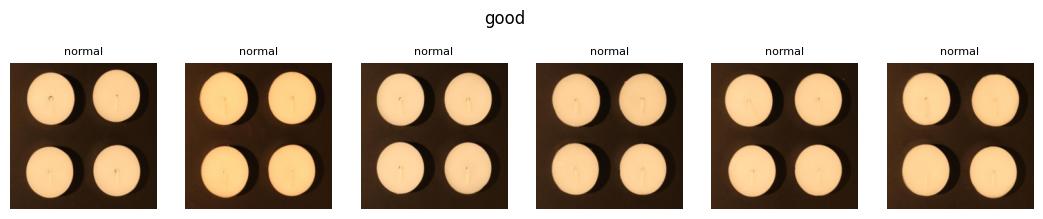

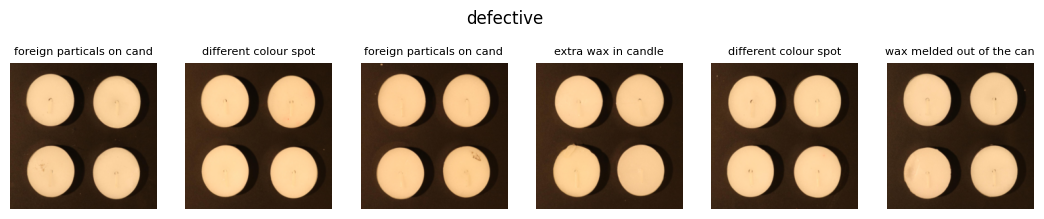

In [0]:
# Let's take a look at some examples. Note how the candle images are batched in groups of 4.
# This isn't the case for all images, but it makes things harder for these cases. Also note how 
# subtle the defects are, they are borderline invisible here.

def show(idx, title):
    fig, axes = plt.subplots(1, len(idx), figsize=(2.2 * len(idx), 2.6))
    for ax, i in zip(axes, idx):
        ax.imshow(images[i].permute(1, 2, 0))
        ax.set_title(defect_type[i][:25], fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


rng = np.random.default_rng(0)
show(rng.choice(train[~defect[train]], 6, replace=False), "good")
show(rng.choice(train[defect[train]], 6, replace=False), "defective")

In [0]:
# The patch knn model is based on DINOv2-base, which is a pretrained vision transformer model. DINOv2 was not trained
# as a classifier, instead it "reduces" the image to a grid of 14x14 "patches". Each patch gets a 768x1 vector, 
# So that DINOv2 is producing a high dimensional representation of each patch of the image (the final output is 768x16x16, plus a 768x1 class token that summarizes the entire image). See the Patch Core idea here: https://arxiv.org/abs/2106.08265 . 
# Read more about DINOv2 here: https://huggingface.co/facebook/dinov2-base

# the patch-knn compares images only to non-defective images. Basically for each patch you find the distance to the
# nearest neighbor patch in the training data. Then you calculate a score based on the highest distance amongst all 
# the patches. If the score is above a certain threshold, we classify the image as defective.

# Thus there is no training, we just use the DINOv2 to generate some features

from transformers import AutoModel


# We get the dino model and put it on the GPU
dino = AutoModel.from_pretrained("facebook/dinov2-base").to(DEVICE).eval()

# These are the mean and standard deviation for the ImageNet dataset, on which DINOv2 was trained
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)    # ImageNet colour statistics
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

@torch.no_grad()
def patch_features(images, batch_size=64):
    out = []
    for batch in images.split(batch_size):
        x = (batch.to(DEVICE).float() / 255 - MEAN) / STD

        # DINOv2 divides each image into a 16 x 16 grid of 14 x 14 pixel patches (256 patches), and outputs
        # a 768-number vector for each one. In front of these it puts one extra vector, the CLS token,
        # which summarizes the whole image. So the hidden output is B x 257 x 768.
        hidden = dino(pixel_values=x).last_hidden_state

        # Keep the 256 patch vectors and drop the CLS token (position 0).
        # float16 (.half()) is a trick for reducing memory requirements
        out.append(hidden[:, 1:].half())

    return torch.cat(out)  # N x 256 x 768, produces the final representation of the image features per patch


# Once we have the feature representation we can the test images

def patch_knn(images, defect, split):
    train_good = (split == "train") & ~defect # We drop the defect images from the training set
    test = split == "test" # We only want the test images. In theory we could add the defective training images
    # but we don't, just to make it a fair comparison with what you will do on your homework
    bank = patch_features(images[train_good]).flatten(0, 1).float()     # all normal patches, stacked
    # This is the line that implements knn. We are only using the nearest neighbor. We could try more, I don't know
    # if it would help much
    scores = [torch.cdist(p.float(), bank).min(dim=1).values.max().item() for p in patch_features(images[test])]
    return defect[test], np.array(scores)


y_test, scores = patch_knn(images, defect, split)

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

candle: AUROC 0.943, recall at 1% FPR 0.42


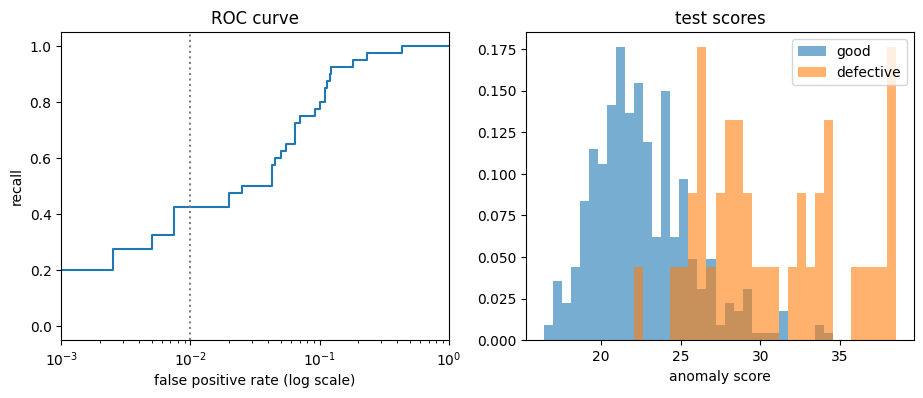

In [0]:
# Now we see how well the model does. We can't really interpret this model probabilistically, so we just look at the
# ROC curve and the recall at 1% false positive rate. 

# A 1% fpr is an approximate benchmark of what might be an acceptable fpr for a real world application where 
# product will be discarded from at inspection. Depending on the stakes we might go for lower or higher

def recall_at_fpr(y, s, fpr_target=0.01):
    fpr, tpr, _ = roc_curve(y, s)
    return np.interp(fpr_target, fpr, tpr)


# For this particular example, at a 1% fpr we are finding 40% of defective items.

print(f"{PRODUCT}: AUROC {roc_auc_score(y_test, scores):.3f}, recall at 1% FPR {recall_at_fpr(y_test, scores):.2f}")

fpr, tpr, _ = roc_curve(y_test, scores)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr)
axes[0].axvline(0.01, color="grey", ls=":")
axes[0].set(xscale="log", xlim=(1e-3, 1), xlabel="false positive rate", ylabel="recall", title="ROC curve")
bins = np.linspace(scores.min(), scores.max(), 40)
axes[1].hist(scores[~y_test], bins, alpha=0.6, density=True, label="good")
axes[1].hist(scores[y_test], bins, alpha=0.6, density=True, label="defective")
axes[1].set(xlabel="anomaly score", title="test scores")
axes[1].legend()
plt.show()

In [0]:
# Candles was just one case. Let's try all of them and see how they compare.

# You will notice that while AUROC and recall at 1% FPR tend to be correlated, there are some products where the AUROC is not great but the recall at 1% is very high, and vice versa. This suggests that it is quite important to think
# about what part of the ROC curve is most important for your application.

rows = {}
for product in PRODUCTS:
    images_p, defect_p, _, split_p = load_product(product)
    y_p, s_p = patch_knn(images_p, defect_p, split_p)
    rows[product] = {"AUROC": roc_auc_score(y_p, s_p), "recall at 1% FPR": recall_at_fpr(y_p, s_p)}
baseline = pd.DataFrame(rows).T
baseline.loc["mean"] = baseline.mean()
baseline

,AUROC,recall at 1% FPR
candle,0.943187,0.42500
capsules,0.853112,0.52500
cashew,0.888125,0.47500
chewinggum,0.983209,0.90000
fryum,0.956000,0.82500
macaroni1,0.803625,0.22500
macaroni2,0.744938,0.22500
pcb1,0.886381,0.40000
pcb2,0.833063,0.45000
pcb3,0.901990,0.50000
